In [ ]:
# ================================
# Basic Libraries
# ================================
import numpy as np
import pandas as pd

# ================================
# Data Visualization
# ================================
import matplotlib.pyplot as plt
import seaborn as sns

# ================================
# Ignore Warnings
# ================================
# ================================
# Train Test Split
# ================================
from sklearn.model_selection import train_test_split

# ================================
# Machine Learning Models
# ================================
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor
import warnings
warnings.filterwarnings("ignore")

# ================================
# Data Preprocessing
# ================================
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# ================================
# Model Evaluation
# ================================
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ================================
# Model Save & Load
# ================================
import joblib
import pickle

# ================================
# Optional (if installed)
# ================================
# from xgboost import XGBRegressor

In [4]:
df = pd.read_csv(r"D:\cp_project_file\House_Price_Project\Indian_House_Price_Dataset_10000.csv")
df.head()

,Property_ID,State,City,Locality,Property_Type,BHK,Bathrooms,Balconies,Size_in_SqFt,Floor_No,...,Clubhouse,Security,Furnished_Status,Age_of_Property,Nearby_School_Distance_KM,Nearby_Hospital_Distance_KM,Metro_Distance_KM,Highway_Distance_KM,Facing,Price_in_Lakhs
0,100001,Gujarat,Vadodara,Alkapuri,Villa,3,2,1,2052,17,...,Yes,No,Furnished,10,3.6,1.1,13.6,15.6,South,211.67
1,100002,Tamil Nadu,Chennai,Anna Nagar,Independent House,1,1,1,3736,0,...,Yes,No,Semi-Furnished,16,4.0,1.4,9.2,10.8,North,265.01
2,100003,West Bengal,Kolkata,Behala,Apartment,4,4,3,630,24,...,Yes,No,Semi-Furnished,17,2.1,0.6,7.0,11.7,North,167.26
3,100004,Maharashtra,Nagpur,Wardha Road,Apartment,3,2,2,2679,16,...,No,Yes,Unfurnished,17,2.3,4.6,0.9,3.1,West,157.48
4,100005,Tamil Nadu,Chennai,Adyar,Apartment,1,1,3,756,16,...,No,Yes,Furnished,22,3.2,0.4,5.0,19.1,East,137.48


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Property_ID                  10000 non-null  int64  
 1   State                        10000 non-null  object 
 2   City                         10000 non-null  object 
 3   Locality                     10000 non-null  object 
 4   Property_Type                10000 non-null  object 
 5   BHK                          10000 non-null  int64  
 6   Bathrooms                    10000 non-null  int64  
 7   Balconies                    10000 non-null  int64  
 8   Size_in_SqFt                 10000 non-null  int64  
 9   Floor_No                     10000 non-null  int64  
 10  Total_Floors                 10000 non-null  int64  
 11  Parking                      10000 non-null  object 
 12  Lift                         10000 non-null  object 
 13  Gym              

In [6]:
df.describe()

,Property_ID,BHK,Bathrooms,Balconies,Size_in_SqFt,Floor_No,Total_Floors,Age_of_Property,Nearby_School_Distance_KM,Nearby_Hospital_Distance_KM,Metro_Distance_KM,Highway_Distance_KM,Price_in_Lakhs
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,105000.50000,2.980500,2.577600,1.986100,2362.258800,12.488500,21.72150,15.002600,2.592380,3.102020,7.537690,10.300170,230.083186
std,2886.89568,1.409084,1.352391,0.813371,1077.644207,7.498406,6.66204,8.982631,1.391809,1.677302,4.269652,5.654764,77.402056
min,100001.00000,1.000000,1.000000,1.000000,500.000000,0.000000,1.00000,0.000000,0.200000,0.200000,0.200000,0.500000,20.000000
25%,102500.75000,2.000000,1.000000,1.000000,1428.000000,6.000000,18.00000,7.000000,1.400000,1.600000,3.800000,5.500000,175.545000
50%,105000.50000,3.000000,2.000000,2.000000,2366.000000,12.000000,23.00000,15.000000,2.600000,3.100000,7.500000,10.400000,227.480000
75%,107500.25000,4.000000,4.000000,3.000000,3300.000000,19.000000,27.00000,23.000000,3.800000,4.500000,11.200000,15.200000,280.805000
max,110000.00000,5.000000,5.000000,3.000000,4200.000000,25.000000,30.00000,30.000000,5.000000,6.000000,15.000000,20.000000,516.310000


In [7]:
# Total duplicate rows
print("Duplicate Rows :", df.duplicated().sum())

Duplicate Rows : 0


In [9]:
# 5. Missing Values
df.isnull().sum()

Property_ID                    0
State                          0
City                           0
Locality                       0
Property_Type                  0
BHK                            0
Bathrooms                      0
Balconies                      0
Size_in_SqFt                   0
Floor_No                       0
Total_Floors                   0
Parking                        0
Lift                           0
Gym                            0
Swimming_Pool                  0
Garden                         0
Clubhouse                      0
Security                       0
Furnished_Status               0
Age_of_Property                0
Nearby_School_Distance_KM      0
Nearby_Hospital_Distance_KM    0
Metro_Distance_KM              0
Highway_Distance_KM            0
Facing                         0
Price_in_Lakhs                 0
dtype: int64

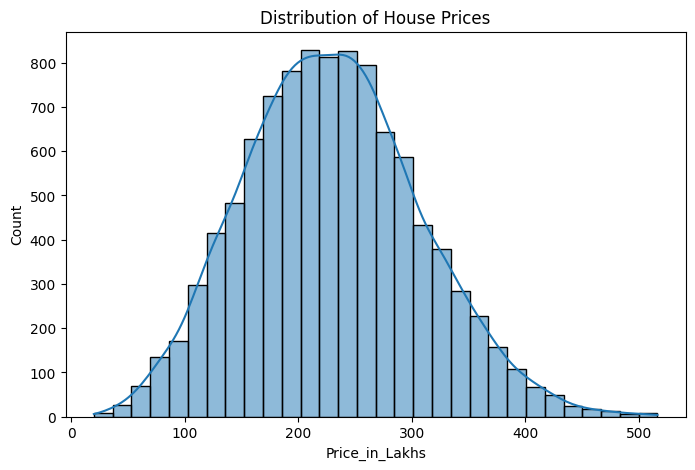

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price_in_Lakhs'], bins=30, kde=True)
plt.title("Distribution of House Prices")
plt.show()


In [11]:
df.describe()

,Property_ID,BHK,Bathrooms,Balconies,Size_in_SqFt,Floor_No,Total_Floors,Age_of_Property,Nearby_School_Distance_KM,Nearby_Hospital_Distance_KM,Metro_Distance_KM,Highway_Distance_KM,Price_in_Lakhs
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,105000.50000,2.980500,2.577600,1.986100,2362.258800,12.488500,21.72150,15.002600,2.592380,3.102020,7.537690,10.300170,230.083186
std,2886.89568,1.409084,1.352391,0.813371,1077.644207,7.498406,6.66204,8.982631,1.391809,1.677302,4.269652,5.654764,77.402056
min,100001.00000,1.000000,1.000000,1.000000,500.000000,0.000000,1.00000,0.000000,0.200000,0.200000,0.200000,0.500000,20.000000
25%,102500.75000,2.000000,1.000000,1.000000,1428.000000,6.000000,18.00000,7.000000,1.400000,1.600000,3.800000,5.500000,175.545000
50%,105000.50000,3.000000,2.000000,2.000000,2366.000000,12.000000,23.00000,15.000000,2.600000,3.100000,7.500000,10.400000,227.480000
75%,107500.25000,4.000000,4.000000,3.000000,3300.000000,19.000000,27.00000,23.000000,3.800000,4.500000,11.200000,15.200000,280.805000
max,110000.00000,5.000000,5.000000,3.000000,4200.000000,25.000000,30.00000,30.000000,5.000000,6.000000,15.000000,20.000000,516.310000


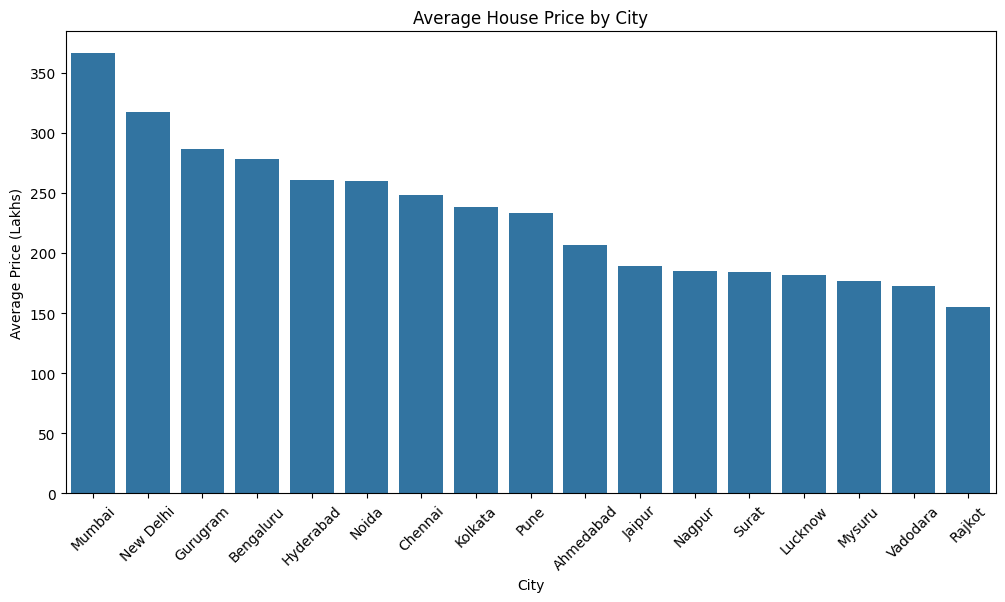

In [12]:
plt.figure(figsize=(12,6))
city_price = df.groupby('City')['Price_in_Lakhs'].mean().sort_values(ascending=False)

sns.barplot(x=city_price.index, y=city_price.values)

plt.xticks(rotation=45)
plt.title("Average House Price by City")
plt.xlabel("City")
plt.ylabel("Average Price (Lakhs)")
plt.show()

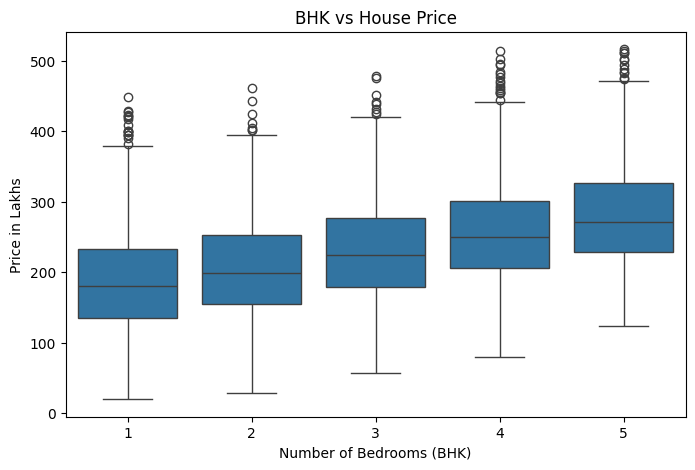

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(x='BHK', y='Price_in_Lakhs', data=df)

plt.title("BHK vs House Price")

plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Price in Lakhs")

plt.show()

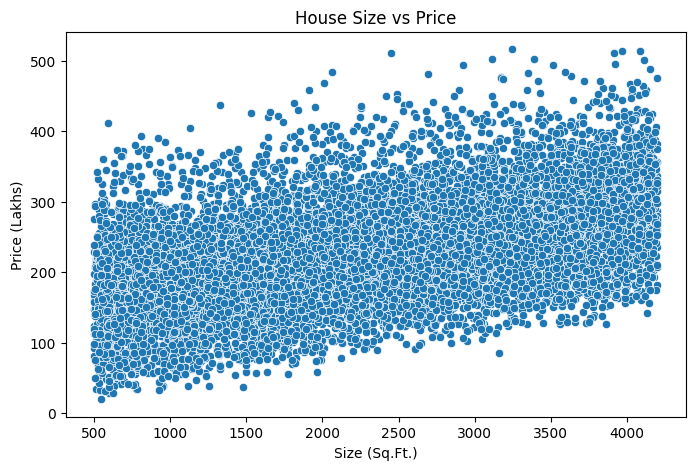

In [14]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='Size_in_SqFt',
    y='Price_in_Lakhs',
    data=df
)

plt.title("House Size vs Price")

plt.xlabel("Size (Sq.Ft.)")
plt.ylabel("Price (Lakhs)")

plt.show()

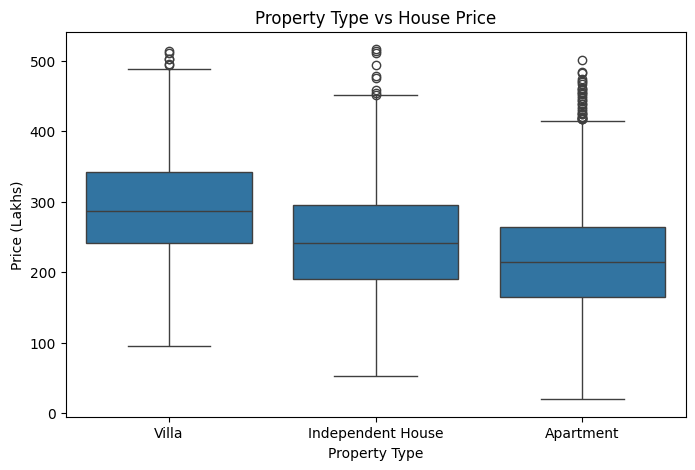

In [15]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Property_Type',
    y='Price_in_Lakhs',
    data=df
)

plt.title("Property Type vs House Price")
plt.xlabel("Property Type")
plt.ylabel("Price (Lakhs)")

plt.show()

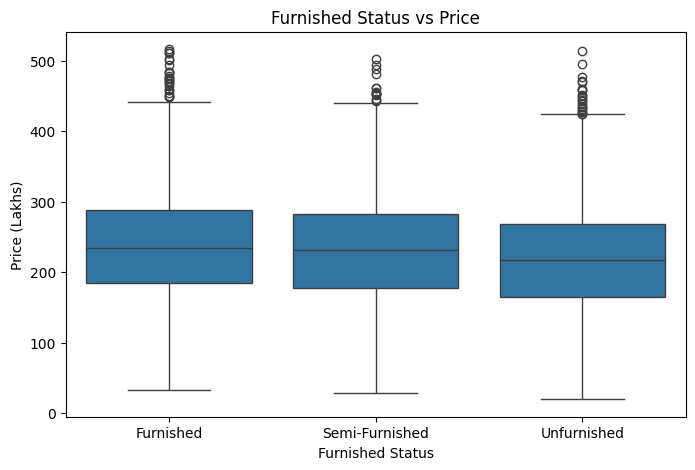

In [16]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Furnished_Status',
    y='Price_in_Lakhs',
    data=df
)

plt.title("Furnished Status vs Price")
plt.xlabel("Furnished Status")
plt.ylabel("Price (Lakhs)")

plt.show()

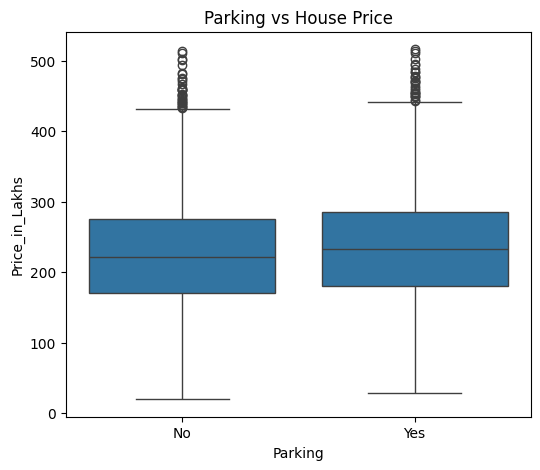

In [17]:
plt.figure(figsize=(6,5))

sns.boxplot(
    x='Parking',
    y='Price_in_Lakhs',
    data=df
)

plt.title("Parking vs House Price")

plt.show()

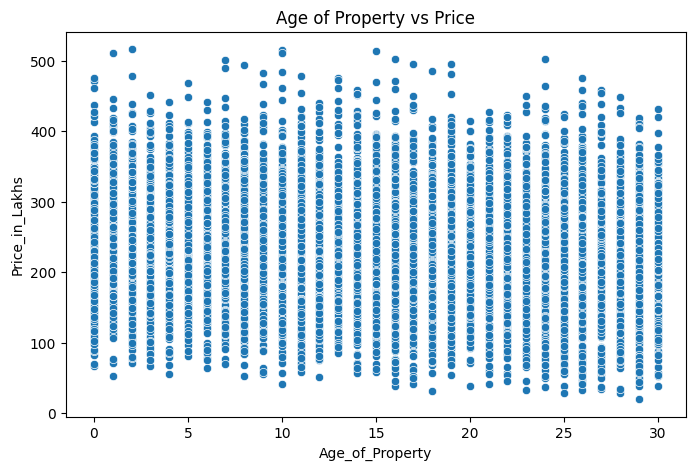

In [18]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='Age_of_Property',
    y='Price_in_Lakhs',
    data=df
)

plt.title("Age of Property vs Price")

plt.show()

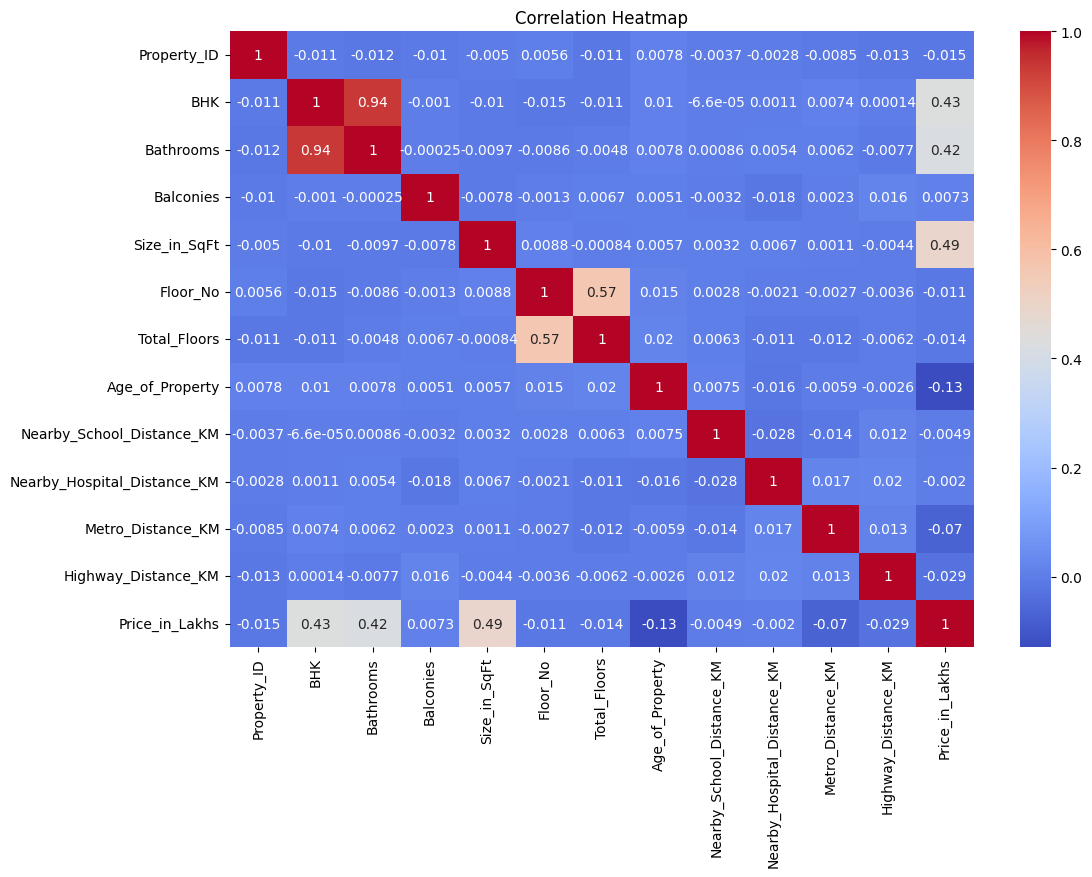

In [19]:
plt.figure(figsize=(12,8))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

In [20]:
X = df.drop('Price_in_Lakhs', axis=1)

y = df['Price_in_Lakhs']

print("X Shape :", X.shape)
print("y Shape :", y.shape)

X Shape : (10000, 25)
y Shape : (10000,)


In [22]:
categorical_cols = X.select_dtypes(include=['object']).columns

numerical_cols = X.select_dtypes(exclude=['object']).columns

print("Categorical Columns")
print(categorical_cols)

print()

print("Numerical Columns")
print(numerical_cols)

Categorical Columns
Index(['State', 'City', 'Locality', 'Property_Type', 'Parking', 'Lift', 'Gym',
       'Swimming_Pool', 'Garden', 'Clubhouse', 'Security', 'Furnished_Status',
       'Facing'],
      dtype='object')

Numerical Columns
Index(['Property_ID', 'BHK', 'Bathrooms', 'Balconies', 'Size_in_SqFt',
       'Floor_No', 'Total_Floors', 'Age_of_Property',
       'Nearby_School_Distance_KM', 'Nearby_Hospital_Distance_KM',
       'Metro_Distance_KM', 'Highway_Distance_KM'],
      dtype='object')


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

X_encoded = preprocessor.fit_transform(X)

print("Encoded Shape :", X_encoded.shape)

Encoded Shape : (10000, 147)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (8000, 147)
X_test  : (2000, 147)
y_train : (8000,)
y_test  : (2000,)


In [26]:
import pandas as pd

X_train_df = pd.DataFrame(X_train.toarray())
X_test_df = pd.DataFrame(X_test.toarray())

print(X_train_df.head())
print()
print(X_test_df.head())

   0    1    2    3    4    5    6    7    8    9    ...  137  138     139  \
0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  1.0  3.0  1098.0   
1  0.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  3.0  1.0  3549.0   
2  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  2.0  1.0   761.0   
3  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  5.0  1.0  1823.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0  ...  2.0  3.0  3723.0   

    140   141   142  143  144   145   146  
0   7.0  19.0  24.0  3.4  6.0   8.6   8.0  
1  19.0  30.0  19.0  4.1  3.3  11.1  11.3  
2   0.0  23.0  11.0  4.5  1.0   4.4  15.1  
3   6.0  13.0   0.0  3.0  4.2  10.0   5.1  
4  25.0  26.0  28.0  1.3  4.7   1.6  14.9  

[5 rows x 147 columns]

   0    1    2    3    4    5    6    7    8    9    ...  137  138     139  \
0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  4.0  2.0  3644.0   
1  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  1.0  1.0  3229.0   
2  1.0  

In [27]:
from sklearn.linear_model import LinearRegression

# Model banana
lr_model = LinearRegression()

# Model ko train karna
lr_model.fit(X_train, y_train)

print("✅ Linear Regression Model Trained Successfully")

✅ Linear Regression Model Trained Successfully


In [28]:
y_pred = lr_model.predict(X_test)

print(y_pred[:10])

[446.31940648 174.10610441 297.77285773  56.12997738 219.6857718
 134.90201405 106.4847865  155.38104236 254.52261365 272.25998104]


In [29]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,443.65,446.319406
1,183.25,174.106104
2,311.68,297.772858
3,61.49,56.129977
4,213.55,219.685772
5,123.35,134.902014
6,112.14,106.484786
7,157.72,155.381042
8,268.95,254.522614
9,264.34,272.259981


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae,2))
print("Mean Squared Error (MSE):", round(mse,2))
print("Root Mean Squared Error (RMSE):", round(rmse,2))
print("R² Score:", round(r2,4))

Mean Absolute Error (MAE): 7.48
Mean Squared Error (MSE): 76.08
Root Mean Squared Error (RMSE): 8.72
R² Score: 0.9875


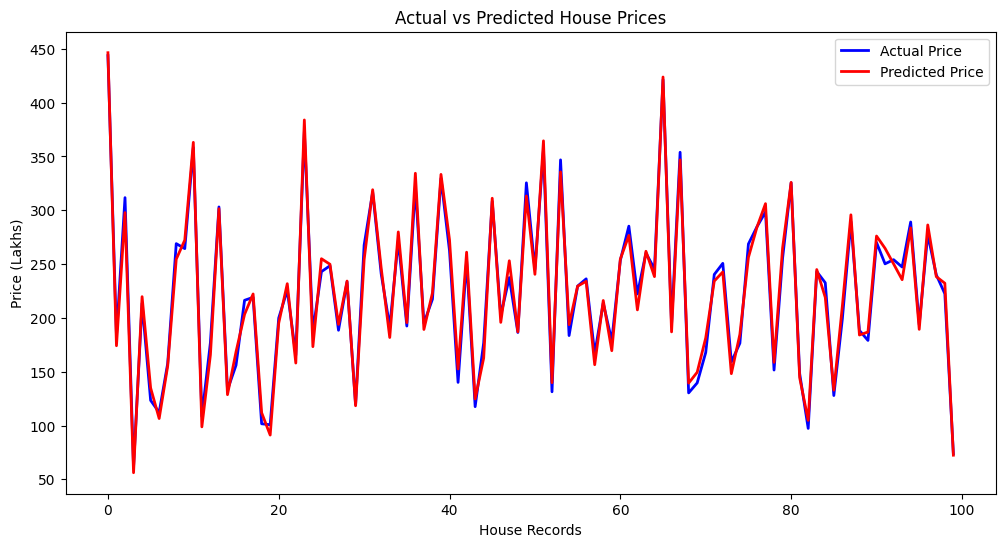

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(y_test.values[:100], label='Actual Price', color='blue', linewidth=2)
plt.plot(y_pred[:100], label='Predicted Price', color='red', linewidth=2)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("House Records")
plt.ylabel("Price (Lakhs)")
plt.legend()

plt.show()

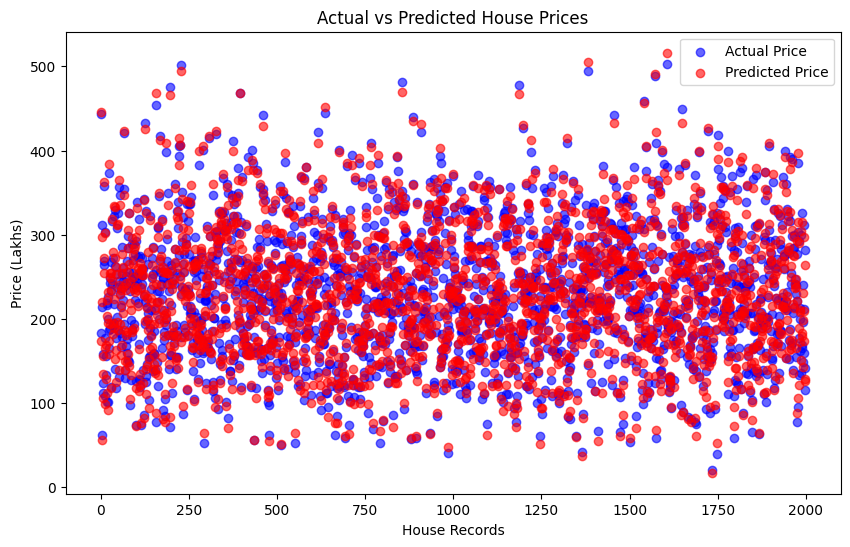

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.scatter(range(len(y_test)), y_test, color='blue', label='Actual Price', alpha=0.6)
plt.scatter(range(len(y_pred)), y_pred, color='red', label='Predicted Price', alpha=0.6)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("House Records")
plt.ylabel("Price (Lakhs)")
plt.legend()

plt.show()

In [33]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

In [37]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np

mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree")
print("MAE :", mae_dt)
print("MSE :", mse_dt)
print("RMSE:", rmse_dt)
print("R2 :", r2_dt)

Decision Tree
MAE : 25.132585
MSE : 1064.8264998500001
RMSE: 32.63167939058608
R2 : 0.8256185409033809


In [36]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [38]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R2 :", r2_rf)

Random Forest
MAE : 17.0227209
MSE : 474.9578363780502
RMSE: 21.793527396409473
R2 : 0.9222184642017786


In [39]:
comparison = pd.DataFrame({
    "Model":["Linear Regression","Decision Tree","Random Forest"],
    "MAE":[mae,mae_dt,mae_rf],
    "RMSE":[rmse,rmse_dt,rmse_rf],
    "R2 Score":[r2,r2_dt,r2_rf]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,7.483221,8.722437,0.987541
1,Decision Tree,25.132585,32.631679,0.825619
2,Random Forest,17.022721,21.793527,0.922218


In [40]:
feature_names = preprocessor.get_feature_names_out()

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_model.coef_
})

coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

coef_df.head(20)

,Feature,Coefficient,Absolute_Coefficient
17,cat__City_Mumbai,96.869358,96.869358
19,cat__City_Nagpur,-58.686574,58.686574
18,cat__City_Mysuru,-40.516972,40.516972
1,cat__State_Gujarat,-40.345003,40.345003
10,cat__City_Bengaluru,39.828623,39.828623
0,cat__State_Delhi,37.553912,37.553912
20,cat__City_New Delhi,36.581379,36.581379
113,cat__Property_Type_Villa,36.477880,36.477880
103,cat__Locality_Vasant Kunj,35.088188,35.088188
111,cat__Property_Type_Apartment,-33.251543,33.251543


In [41]:
import joblib

joblib.dump(lr_model, "house_price_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("Model Saved Successfully")

Model Saved Successfully


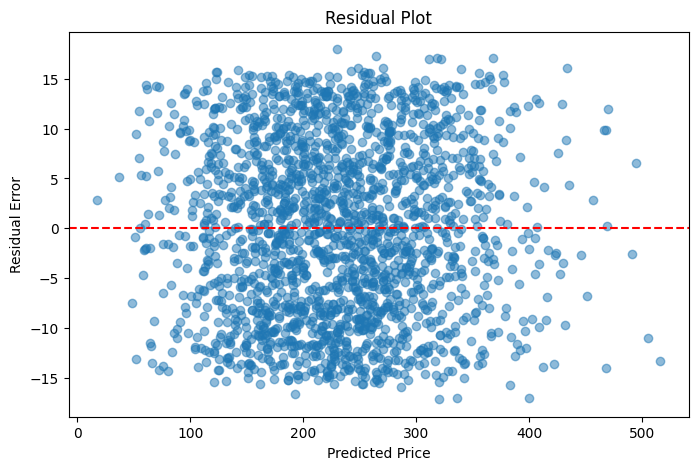

In [42]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residual Error")
plt.title("Residual Plot")

plt.show()

In [43]:
print(type(preprocessor))
print(preprocessor)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
ColumnTransformer(remainder='passthrough',
                  transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 Index(['State', 'City', 'Locality', 'Property_Type', 'Parking', 'Lift', 'Gym',
       'Swimming_Pool', 'Garden', 'Clubhouse', 'Security', 'Furnished_Status',
       'Facing'],
      dtype='object'))])


In [44]:
import joblib

joblib.dump(lr_model, "house_price_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("✅ Model and Preprocessor Saved Successfully")

✅ Model and Preprocessor Saved Successfully


In [46]:
# ============================================
# MODEL COMPARISON
# ============================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mae,
        mae_dt,
        mae_rf
    ],
    "RMSE": [
        rmse,
        rmse_dt,
        rmse_rf
    ],
    "R2 Score": [
        r2,
        r2_dt,
        r2_rf
    ]
})

print(comparison)


# ============================================
# FIND BEST PERFORMANCE MODEL
# ============================================

best_model_name = comparison.loc[
    comparison["R2 Score"].idxmax(),
    "Model"
]

models = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

best_model = models[best_model_name]


# ============================================
# SAVE BEST MODEL
# ============================================

import joblib

joblib.dump(best_model, "house_price_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")


# ============================================
# FINAL OUTPUT
# ============================================

print("\nBest Performance Model :", best_model_name)

print("\n======================================")
print("BEST MODEL SAVED SUCCESSFULLY")
print("======================================")

print("Best Model Name :", best_model_name)
print("Saved File      : house_price_model.pkl")

               Model        MAE       RMSE  R2 Score
0  Linear Regression   7.483221   8.722437  0.987541
1      Decision Tree  25.132585  32.631679  0.825619
2      Random Forest  17.022721  21.793527  0.922218

Best Performance Model : Linear Regression

BEST MODEL SAVED SUCCESSFULLY
Best Model Name : Linear Regression
Saved File      : house_price_model.pkl


In [51]:
# ==========================================================
# FINAL HOUSE PRICE PREDICTION - SAMPLE
# ==========================================================

import pandas as pd
import joblib

# Load saved model and preprocessor
model = joblib.load("house_price_model.pkl")
preprocessor = joblib.load("preprocessor.pkl")

# ----------------------------------------------------------
# SAMPLE HOUSE INPUT
# ----------------------------------------------------------

input_data = pd.DataFrame({
    "Property_ID": [10001],
    "State": ["Gujarat"],
    "City": ["Ahmedabad"],
    "Locality": ["Satellite"],
    "Property_Type": ["Apartment"],
    "BHK": [3],
    "Bathrooms": [2],
    "Balconies": [2],
    "Size_in_SqFt": [1500],
    "Floor_No": [5],
    "Total_Floors": [10],
    "Parking": ["Yes"],
    "Lift": ["Yes"],
    "Gym": ["Yes"],
    "Swimming_Pool": ["No"],
    "Garden": ["Yes"],
    "Clubhouse": ["Yes"],
    "Security": ["Yes"],
    "Furnished_Status": ["Semi-Furnished"],
    "Age_of_Property": [5],
    "Nearby_School_Distance_KM": [2],
    "Nearby_Hospital_Distance_KM": [3],
    "Metro_Distance_KM": [4],
    "Highway_Distance_KM": [5],
    "Facing": ["East"]
})

# ----------------------------------------------------------
# PREPROCESS & PREDICT
# ----------------------------------------------------------

input_encoded = preprocessor.transform(input_data)

prediction = model.predict(input_encoded)

# ----------------------------------------------------------
# DISPLAY RESULT
# ----------------------------------------------------------

print("=" * 60)
print("          HOUSE PRICE PREDICTION RESULT")
print("=" * 60)

print("\nPROPERTY DETAILS")
print("-" * 60)

print("State          :", input_data["State"].iloc[0])
print("City           :", input_data["City"].iloc[0])
print("Locality       :", input_data["Locality"].iloc[0])
print("Property Type  :", input_data["Property_Type"].iloc[0])
print("BHK            :", input_data["BHK"].iloc[0])
print("Bathrooms      :", input_data["Bathrooms"].iloc[0])
print("Size           :", input_data["Size_in_SqFt"].iloc[0], "Sq.Ft.")
print("Furnished      :", input_data["Furnished_Status"].iloc[0])
print("Parking        :", input_data["Parking"].iloc[0])
print("Property Age   :", input_data["Age_of_Property"].iloc[0], "Years")

print("\n" + "=" * 60)
print("PREDICTED HOUSE PRICE")
print("=" * 60)

print(f"\n₹ {prediction[0]:.2f} Lakhs")

print("\n" + "=" * 60)
print("Prediction completed successfully!")
print("=" * 60)

          HOUSE PRICE PREDICTION RESULT

PROPERTY DETAILS
------------------------------------------------------------
State          : Gujarat
City           : Ahmedabad
Locality       : Satellite
Property Type  : Apartment
BHK            : 3
Bathrooms      : 2
Size           : 1500 Sq.Ft.
Furnished      : Semi-Furnished
Parking        : Yes
Property Age   : 5 Years

PREDICTED HOUSE PRICE

₹ 209.43 Lakhs

Prediction completed successfully!
